<a href="https://colab.research.google.com/github/AhmadFebriyan5/Studi-Kasus_Machine-Learning/blob/main/3_Career_and_Competition_in_Industrial_Era_with_GIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Studi Kasus GIS: Validasi Koordinat dan Analisis Sebaran Aset Fasilitas Publik



=== DATA AWAL ===


,id,nama,jenis,latitude,longitude
0,1,RS Sehat,Rumah Sakit,-7.800,110.370
1,2,SD Harapan,Sekolah,-7.805,110.375
2,3,Taman Kota,Taman,-7.810,110.380
3,4,Puskesmas A,Puskesmas,-7.815,110.365
4,5,SMP Nusantara,Sekolah,-7.820,110.385
5,6,Kantor Layanan,Kantor,-7.825,110.375
6,7,Taman Barat,Taman,-7.805,110.360
7,8,Klinik B,Klinik,-7.830,110.390
8,9,Sekolah Timur,Sekolah,-7.810,110.410
9,10,Aset Kosong,Kantor,NaN,110.370


\n=== RINGKASAN VALIDASI ===


,Pemeriksaan,Jumlah
0,Data awal,13
1,Koordinat kosong,1
2,Koordinat di luar rentang,1
3,Duplikat terdeteksi,1
4,Data unik dengan koordinat valid,10
5,Aset dalam wilayah,8
6,Aset di luar wilayah,2


\n=== DATA KOORDINAT KOSONG ===


...

,id,nama,jenis,latitude,longitude
0,1,RS Sehat,Rumah Sakit,-7.800,110.370
1,2,SD Harapan,Sekolah,-7.805,110.375
2,3,Taman Kota,Taman,-7.810,110.380
3,4,Puskesmas A,Puskesmas,-7.815,110.365
4,5,SMP Nusantara,Sekolah,-7.820,110.385
5,6,Kantor Layanan,Kantor,-7.825,110.375
6,7,Taman Barat,Taman,-7.805,110.360
7,8,Klinik B,Klinik,-7.830,110.390


\n=== ASET DI LUAR WILAYAH ===


,id,nama,jenis,latitude,longitude
8,9,Sekolah Timur,Sekolah,-7.81,110.41
11,12,Aset Luar Kota,Rumah Sakit,-7.80,110.50


\n=== JUMLAH ASET PER JENIS ===


,jenis,jumlah_aset
4,Sekolah,2
5,Taman,2
1,Klinik,1
0,Kantor,1
3,Rumah Sakit,1
2,Puskesmas,1


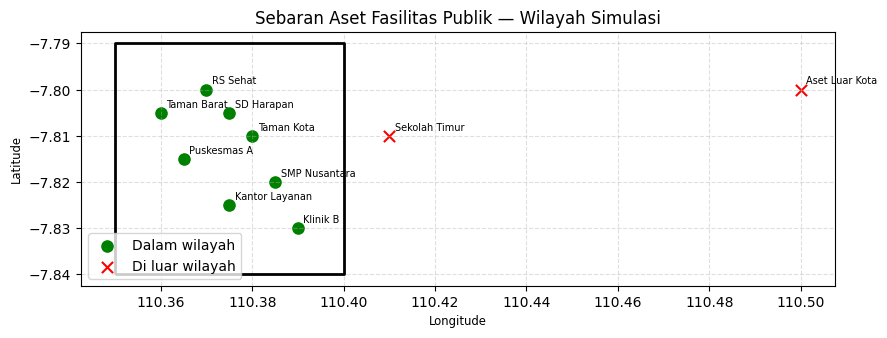

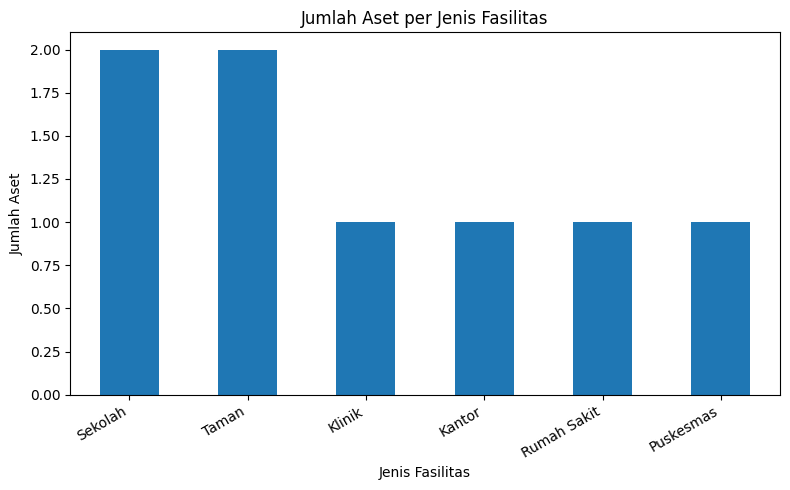

\nFile tersimpan: aset_tervalidasi.csv dan aset_tervalidasi.geojson


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# Studi Kasus GIS: Validasi Koordinat dan Analisis Sebaran Aset Fasilitas Publik


!pip -q install geopandas shapely

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon
from IPython.display import display

# 1. Dataset simulasi
data = [
    {"id": 1, "nama": "RS Sehat",        "jenis": "Rumah Sakit", "latitude": -7.8000, "longitude": 110.3700},
    {"id": 2, "nama": "SD Harapan",      "jenis": "Sekolah",     "latitude": -7.8050, "longitude": 110.3750},
    {"id": 3, "nama": "Taman Kota",      "jenis": "Taman",       "latitude": -7.8100, "longitude": 110.3800},
    {"id": 4, "nama": "Puskesmas A",     "jenis": "Puskesmas",   "latitude": -7.8150, "longitude": 110.3650},
    {"id": 5, "nama": "SMP Nusantara",   "jenis": "Sekolah",     "latitude": -7.8200, "longitude": 110.3850},
    {"id": 6, "nama": "Kantor Layanan",  "jenis": "Kantor",      "latitude": -7.8250, "longitude": 110.3750},
    {"id": 7, "nama": "Taman Barat",     "jenis": "Taman",       "latitude": -7.8050, "longitude": 110.3600},
    {"id": 8, "nama": "Klinik B",        "jenis": "Klinik",      "latitude": -7.8300, "longitude": 110.3900},
    {"id": 9, "nama": "Sekolah Timur",   "jenis": "Sekolah",     "latitude": -7.8100, "longitude": 110.4100},
    {"id": 10, "nama": "Aset Kosong",    "jenis": "Kantor",      "latitude": None,    "longitude": 110.3700},
    {"id": 11, "nama": "Koordinat Salah","jenis": "Taman",       "latitude": -95.0000,"longitude": 110.3700},
    {"id": 12, "nama": "Aset Luar Kota", "jenis": "Rumah Sakit", "latitude": -7.8000, "longitude": 110.5000},
    {"id": 13, "nama": "RS Sehat",       "jenis": "Rumah Sakit", "latitude": -7.8000, "longitude": 110.3700},
]
df = pd.DataFrame(data)
print("=== DATA AWAL ===")
display(df)

# 2. Validasi koordinat
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

missing = df[df[["latitude", "longitude"]].isna().any(axis=1)].copy()
lengkap = df.dropna(subset=["latitude", "longitude"]).copy()

rentang_valid = (
    lengkap["latitude"].between(-90, 90)
    & lengkap["longitude"].between(-180, 180)
)
koordinat_tidak_valid = lengkap[~rentang_valid].copy()
df_valid = lengkap[rentang_valid].copy()

# 3. Deteksi duplikat berdasarkan nama, jenis, dan koordinat
duplikat = df_valid[
    df_valid.duplicated(
        subset=["nama", "jenis", "latitude", "longitude"],
        keep="first"
    )
].copy()
df_unik = df_valid.drop_duplicates(
    subset=["nama", "jenis", "latitude", "longitude"],
    keep="first"
).copy()

# 4. Konversi ke GeoDataFrame (WGS 84)
gdf = gpd.GeoDataFrame(
    df_unik,
    geometry=[Point(lon, lat) for lon, lat in zip(df_unik["longitude"], df_unik["latitude"])],
    crs="EPSG:4326"
)

# 5. Batas wilayah simulasi (bukan batas administrasi resmi)
batas = Polygon([
    (110.350, -7.840),
    (110.400, -7.840),
    (110.400, -7.790),
    (110.350, -7.790),
    (110.350, -7.840)
])
wilayah = gpd.GeoDataFrame({"wilayah": ["Wilayah Studi"]}, geometry=[batas], crs="EPSG:4326")

dalam = gdf[gdf.geometry.intersects(batas)].copy()
luar = gdf[~gdf.geometry.intersects(batas)].copy()

# 6. Tampilkan ringkasan validasi
ringkasan = pd.DataFrame({
    "Pemeriksaan": [
        "Data awal",
        "Koordinat kosong",
        "Koordinat di luar rentang",
        "Duplikat terdeteksi",
        "Data unik dengan koordinat valid",
        "Aset dalam wilayah",
        "Aset di luar wilayah"
    ],
    "Jumlah": [
        len(df),
        len(missing),
        len(koordinat_tidak_valid),
        len(duplikat),
        len(gdf),
        len(dalam),
        len(luar)
    ]
})
print("\\n=== RINGKASAN VALIDASI ===")
display(ringkasan)

print("\\n=== DATA KOORDINAT KOSONG ===")
display(missing)
print("\\n=== DATA KOORDINAT TIDAK VALID ===")
display(koordinat_tidak_valid)
print("\\n=== DATA DUPLIKAT ===")
display(duplikat)
print("\\n=== ASET DALAM WILAYAH ===")
display(dalam[["id", "nama", "jenis", "latitude", "longitude"]])
print("\\n=== ASET DI LUAR WILAYAH ===")
display(luar[["id", "nama", "jenis", "latitude", "longitude"]])

# 7. Statistik jenis fasilitas dalam wilayah
statistik = (
    dalam.groupby("jenis")
    .size()
    .reset_index(name="jumlah_aset")
    .sort_values("jumlah_aset", ascending=False)
)
print("\\n=== JUMLAH ASET PER JENIS ===")
display(statistik)

# 8. Visualisasi peta
fig, ax = plt.subplots(figsize=(9, 7))
wilayah.boundary.plot(ax=ax, color="black", linewidth=2)
if not dalam.empty:
    dalam.plot(ax=ax, color="green", markersize=65, label="Dalam wilayah")
if not luar.empty:
    luar.plot(ax=ax, color="red", marker="x", markersize=65, label="Di luar wilayah")

for _, row in gdf.iterrows():
    ax.annotate(row["nama"], (row.geometry.x, row.geometry.y),
                xytext=(4, 4), textcoords="offset points", fontsize=7)

ax.set_title("Sebaran Aset Fasilitas Publik — Wilayah Simulasi")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 9. Grafik jumlah aset per jenis
statistik.plot(
    x="jenis", y="jumlah_aset", kind="bar", legend=False, figsize=(8, 5)
)
plt.title("Jumlah Aset per Jenis Fasilitas")
plt.xlabel("Jenis Fasilitas")
plt.ylabel("Jumlah Aset")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 10. Ekspor hasil
kolom = ["id", "nama", "jenis", "latitude", "longitude"]
dalam[kolom].to_csv("aset_tervalidasi.csv", index=False)
dalam.to_file("aset_tervalidasi.geojson", driver="GeoJSON")
print("\\nFile tersimpan: aset_tervalidasi.csv dan aset_tervalidasi.geojson")

